# Results CSV Schema Scan and DuckDB Load

This notebook scans CSV headers in the results folder, reports schema/order differences, and prepares a conditional DuckDB load after your confirmation.

## 1. List CSV Files in `#file:results`


In [38]:
from pathlib import Path

# This directory is part of the upstream pacslab/serverless-performance-modeling
# checkout, which README.md says to pull into this tertiary-repo folder.
RESULTS_DIR = Path("experiments/results")
csv_files = sorted(RESULTS_DIR.glob("*.csv"))

print(f"Results folder: {RESULTS_DIR}")
print(f"CSV files found: {len(csv_files)}")
for path in csv_files:
    print(path.name)

Results folder: mahmoudi_et_al/experiments/results
CSV files found: 28
res-01-2020-01-06_20-44-57.csv
res-01-2020-01-07_20-47-22.csv
res-01-2020-01-08_02-57-35.csv
res-01-2020-01-08_21-30-40.csv
res-01-2020-01-09_02-17-42.csv
res-01-2020-01-09_19-59-16.csv
res-01-2020-01-10_00-54-02.csv
res-01-2020-01-15_23-45-39.csv
res-01-2020-04-24_17-53-33.csv
res-01-2020-04-26_08-14-11.csv
res-01-2020-04-28_01-05-42.csv
res-01-2020-04-29_06-57-30.csv
res-01-2020-05-01_20-34-13.csv
res-01-2020-05-03_04-48-10.csv
res-01-2020-05-07_22-21-26.csv
res-01-2020-05-11_08-34-50.csv
res-01-2020-05-12_21-35-23.csv
res-01-2020-05-14_19-26-46.csv
res-01-2020-05-17_04-13-06.csv
res-01-2020-05-23_20-42-58.csv
res-01-2020-05-26_01-31-35.csv
res-01-2020-05-28_01-57-40.csv
res-01-2020-06-04_23-02-14.csv
res-01-2020-06-06_22-39-19.csv
res-01-2020-06-09_01-04-58.csv
res-01-2020-06-10_22-20-08.csv
res-01-2020-06-13_23-39-35.csv
res-01-2020-06-18_23-36-37.csv


## 2. Define Expected Schema and Normalization Rules


In [45]:
# Expected schema as provided (leading comma implies an empty first column name).
expected_columns_raw = [
    "",
    "is_cold",
    "cpu_info",
    "inst_id",
    "inst_priv_ip",
    "new_id",
    "exist_id",
    "uptime",
    "vm_id",
    "vm_priv_ip",
    "vm_pub_ip",
    "start_time",
    "end_time",
    "elapsed_time",
    "aws_duration",
    "aws_billed_duration",
    "aws_max_mem",
    "io_speed",
    "client_start_time",
    "client_end_time",
    "client_elapsed_time",
]


def normalize_col(name: str) -> str:
    if name is None:
        return ""
    name = str(name).strip().lower()
    if name in {"", "unnamed: 0", "unnamed: 0.0"}:
        return "column00"
    return name


expected_columns_norm = [normalize_col(c) for c in expected_columns_raw]
expected_columns_output = expected_columns_norm[:]

## 3. Scan Headers Across Files and Detect Column Order/Presence Differences


In [46]:
import pandas as pd

rows = []
header_signatures = {}

for path in csv_files:
    df_head = pd.read_csv(path, nrows=0)
    raw_cols = list(df_head.columns)
    norm_cols = [normalize_col(c) for c in raw_cols]

    missing = sorted(set(expected_columns_norm) - set(norm_cols))
    extra = sorted(set(norm_cols) - set(expected_columns_norm))
    order_ok = norm_cols == expected_columns_norm

    sig = tuple(norm_cols)
    header_signatures.setdefault(sig, []).append(path.name)

    rows.append(
        {
            "file": path.name,
            "col_count": len(norm_cols),
            "missing": missing,
            "extra": extra,
            "order_ok": order_ok,
        }
    )

schema_report = pd.DataFrame(rows).sort_values("file", ignore_index=True)
schema_report

,file,col_count,missing,extra,order_ok
0,res-01-2020-01-06_20-44-57.csv,21,[],[],False
1,res-01-2020-01-07_20-47-22.csv,21,[],[],False
2,res-01-2020-01-08_02-57-35.csv,21,[],[],False
3,res-01-2020-01-08_21-30-40.csv,21,[],[],False
4,res-01-2020-01-09_02-17-42.csv,21,[],[],False
5,res-01-2020-01-09_19-59-16.csv,21,[],[],False
6,res-01-2020-01-10_00-54-02.csv,21,[],[],False
7,res-01-2020-01-15_23-45-39.csv,21,[],[],False
8,res-01-2020-04-24_17-53-33.csv,21,[],[],True
9,res-01-2020-04-26_08-14-11.csv,21,[],[],True


## 4. Summarize Schema Variations for Confirmation


In [47]:
summary = {
    "total_files": len(schema_report),
    "order_ok": int(schema_report["order_ok"].sum()),
    "order_mismatch": int((~schema_report["order_ok"]).sum()),
    "any_missing": int(schema_report["missing"].astype(bool).sum()),
    "any_extra": int(schema_report["extra"].astype(bool).sum()),
}
summary

signature_rows = []
for sig, files in header_signatures.items():
    signature_rows.append(
        {
            "signature_size": len(sig),
            "files": len(files),
            "example_file": files[0],
            "signature": list(sig),
        }
    )

signature_report = pd.DataFrame(signature_rows).sort_values(
    ["files", "signature_size"], ascending=[False, True], ignore_index=True
)

signature_report

,signature_size,files,example_file,signature
0,21,20,res-01-2020-04-24_17-53-33.csv,"[column00, is_cold, cpu_info, inst_id, inst_pr..."
1,21,8,res-01-2020-01-06_20-44-57.csv,"[column00, aws_billed_duration, aws_duration, ..."


## 5. Conditional: Load CSVs into DuckDB with Column Alignment (Post-Confirmation)

Set `CONFIRM_LOAD = True` only after you confirm that any schema differences should be handled with alignment.

In [50]:
import duckdb
from collections import OrderedDict

CONFIRM_LOAD = True

if not CONFIRM_LOAD:
    raise SystemExit("Set CONFIRM_LOAD = True after confirming schema alignment.")

DB_PATH = RESULTS_DIR / "results.duckdb"
TABLE_NAME = "results"

con = duckdb.connect(str(DB_PATH))

# Load with DuckDB using union_by_name to align differing column orders.
file_list = [str(p) for p in csv_files]
rel = con.read_csv(file_list, header=True, union_by_name=True, filename=True)

# Ensure expected columns exist and enforce a stable column order.
rel_cols = [c.lower() for c in rel.columns]
missing = [c for c in expected_columns_output if c not in rel_cols]
if missing:
    con.close()
    raise SystemExit(f"Missing expected columns: {missing}")

select_cols = ", ".join(expected_columns_output)
rel = rel.project(f"{select_cols}, filename AS __source_file")

con.execute(f"DROP TABLE IF EXISTS {TABLE_NAME}")
con.execute(f"CREATE TABLE {TABLE_NAME} AS SELECT * FROM rel")
con.close()
print(f"Loaded CSVs into {DB_PATH}::{TABLE_NAME}")

Loaded CSVs into mahmoudi_et_al/experiments/results/results.duckdb::results


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Warm-only tail factor
Duration column: client_elapsed_time
Total warm values: 1484468
Median warm duration: 2084.350348 ms
p95: value=2310.485280 ms, p95/median=1.1085, <=p95=1410244, >p95=74224
p99: value=2477.939763 ms, p99/median=1.1888, <=p99=1469623, >p99=14845
p99.9: value=2632.275582 ms, p99.9/median=1.2629, <=p99.9=1482983, >p99.9=1485
p99.99: value=4099.927910 ms, p99.99/median=1.9670, <=p99.99=1484319, >p99.99=149


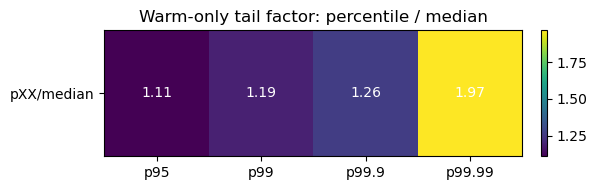

In [1]:
# Tail influence heatmap (warm-only) from DuckDB results
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

DB_PATH = "experiments/results/results.duckdb"
TABLE_NAME = "results"

duration_candidates = ["client_elapsed_time"]
is_cold_col = "is_cold"

con = duckdb.connect(str(DB_PATH))
cols = [c[0] for c in con.execute(f"PRAGMA table_info('{TABLE_NAME}')").fetchall()]
print(cols)
con.close()

duration_col = "client_elapsed_time"

df = duckdb.connect(str(DB_PATH)).execute(
    f"SELECT {duration_col} AS duration, {is_cold_col} AS is_cold FROM {TABLE_NAME}"
    ).df()

df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
df["duration"] = df["duration"] * 1000
df = df.dropna(subset=["duration"])

is_cold_raw = df["is_cold"].astype(str).str.lower()
warm = df.loc[is_cold_raw.isin(["false", "0", "no"]), "duration"]
if warm.empty:
    raise ValueError("No warm-start rows found (is_cold == false).")

percentiles = [95, 99, 99.9, 99.99]
p_values = np.percentile(warm.to_numpy(), percentiles)
median = float(np.median(warm.to_numpy()))
if not np.isfinite(median) or median <= 0:
    raise ValueError(f"Invalid median warm duration: {median}")

factors = []
counts = []
for p, v in zip(percentiles, p_values):
    factor = (v / median) if np.isfinite(v) else np.nan
    factors.append(factor)
    counts.append((int((warm <= v).sum()), int((warm > v).sum())))

print("Warm-only tail factor")
print(f"Duration column: {duration_col}")
print(f"Total warm values: {len(warm)}")
print(f"Median warm duration: {median:.6f} ms")
for p, v, f, (n_in, n_tail) in zip(percentiles, p_values, factors, counts):
    print(f"p{p}: value={v:.6f} ms, p{p}/median={f:.4f}, <=p{p}={n_in}, >p{p}={n_tail}")

fig, ax = plt.subplots(figsize=(6, 2))
heat = np.array([factors])
im = ax.imshow(heat, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(percentiles)))
ax.set_xticklabels([f"p{p}" for p in percentiles])
ax.set_yticks([0])
ax.set_yticklabels(["pXX/median"])

for j, val in enumerate(factors):
    ax.text(j, 0, f"{val:.2f}", ha="center", va="center", color="white")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.title("Warm-only tail factor: percentile / median")
plt.tight_layout()
plt.show()

<notebook cell>:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


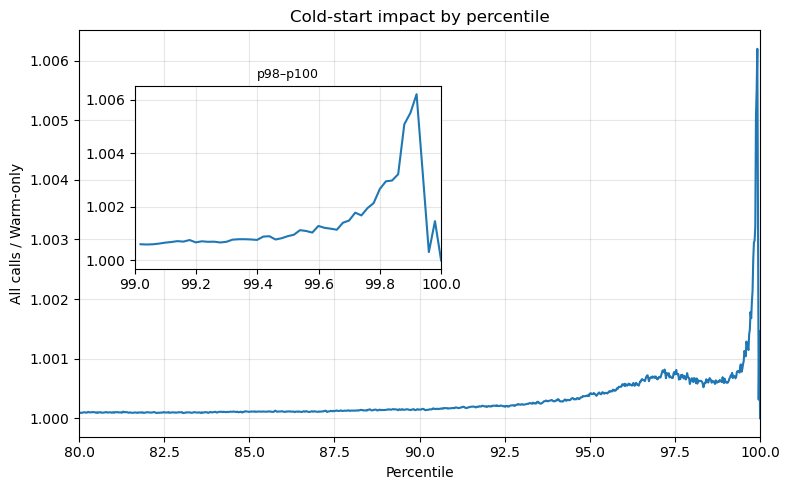

In [53]:
# Percentile ratio: all calls vs warm-only (p80 to p100)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

df2 = duckdb.connect(str(DB_PATH)).execute(
    f"SELECT {duration_col} AS duration, {is_cold_col} AS is_cold FROM {TABLE_NAME}"
).df()

df2["duration"] = pd.to_numeric(df2["duration"], errors="coerce")
df2 = df2.dropna(subset=["duration"])

is_cold_raw = df2["is_cold"].astype(str).str.lower()
warm_mask = is_cold_raw.isin(["false", "0", "no"])

dur_all = df2["duration"].to_numpy()
dur_warm = df2.loc[warm_mask, "duration"].to_numpy()
if len(dur_warm) == 0:
    raise ValueError("No warm-start rows found (is_cold == false).")

percentile_grid = np.linspace(80, 100, 1000)
q_all = np.percentile(dur_all, percentile_grid)
q_warm = np.percentile(dur_warm, percentile_grid)
ratio = q_all / q_warm

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(percentile_grid, ratio)
ax.set_xlim(80, 100)
ax.set_xlabel("Percentile")
ax.set_ylabel("All calls / Warm-only")
ax.set_title("Cold-start impact by percentile")
ax.grid(True, alpha=0.3)

# Zoomed inset for p98 to p100
axins = inset_axes(ax, width="45%", height="45%", loc="upper left", borderpad=4)
mask = (percentile_grid >= 99) & (percentile_grid <= 100)
axins.plot(percentile_grid[mask], ratio[mask])
axins.set_xlim(99, 100)
axins.grid(True, alpha=0.3)
axins.set_title("p98–p100", fontsize=9)

plt.tight_layout()
plt.show()

 hour      n p50.0_count p95.0_count p99.0_count p99.9_count p100.0_count
    0 135935       67968      129139      134576      135800       135922
    1  85951       42976       81654       85092       85866        85943
    2  56681       28341       53847       56115       56625        56676
    3  23861       11931       22668       23623       23838        23859
    4  25142       12571       23885       24891       25117        25140
    5  26065       13033       24762       25805       26039        26063
    6  26116       13058       24811       25855       26090        26114
    7  23628       11814       22447       23392       23605        23626
    8  22143       11072       21036       21922       22121        22141
    9  20437       10219       19416       20233       20417        20435
   10  20451       10226       19429       20247       20431        20449
   11  20281       10141       19267       20079       20261        20279
   12  20316       10158       19301  

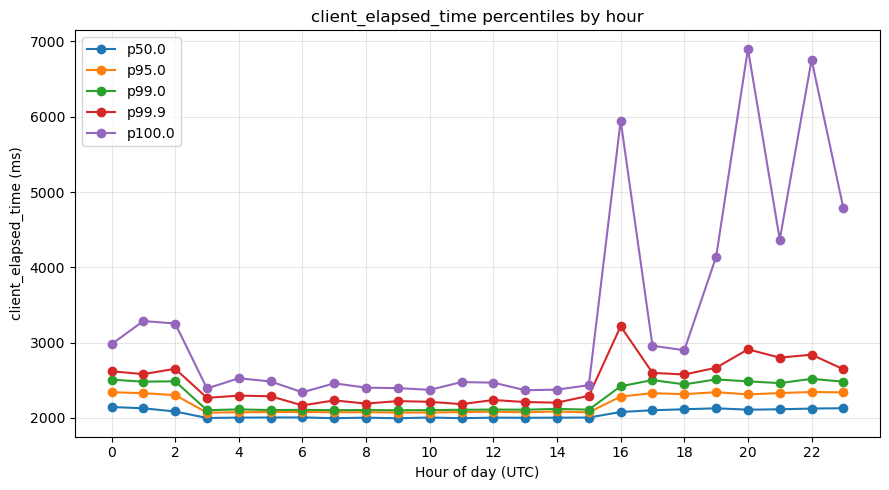

In [3]:
# Intra-day percentiles by hour (client_elapsed_time)
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = globals().get("DB_PATH", "experiments/results/results.duckdb")
TABLE_NAME = globals().get("TABLE_NAME", "results")

percentiles = [0.50, 0.95, 0.99, 0.999, 0.9999]

df_time = duckdb.connect(str(DB_PATH)).execute(
    f"SELECT client_elapsed_time AS latency, client_start_time AS start_time FROM {TABLE_NAME} where is_cold = 'false'"
).df()

df_time["latency_ms"] = pd.to_numeric(df_time["latency"], errors="coerce") * 1000
start_ts = pd.to_numeric(df_time["start_time"], errors="coerce")

mask = np.isfinite(df_time["latency_ms"]) & np.isfinite(start_ts)
df_time = df_time.loc[mask].copy()

if df_time.empty:
    print("No valid latency/start_time rows found.")
else:
    ts_vals = start_ts.loc[mask].to_numpy()
    is_ms = ts_vals >= 1_000_000_000_000
    ts_seconds = np.where(is_ms, ts_vals / 1000.0, ts_vals)

    df_time["timestamp"] = pd.to_datetime(ts_seconds, unit="s", utc=True)
    df_time["hour"] = df_time["timestamp"].dt.hour

    grouped = df_time.groupby("hour", dropna=False)
    counts = grouped.size().rename("n").reset_index()

    quant = grouped["latency_ms"].quantile(percentiles).reset_index()
    quant = quant.rename(columns={"level_1": "percentile", "latency_ms": "value"})

    stats = quant.pivot_table(
        index="hour",
        columns="percentile",
        values="value",
        aggfunc="first",
    ).reset_index()

    stats = stats.merge(counts, on="hour", how="left")

    full_hours = pd.DataFrame({"hour": list(range(24))})
    stats = full_hours.merge(stats, on="hour", how="left")

    count_table = stats[["hour", "n"]].copy()
    for p in percentiles:
        count_col = f"p{p*100:.1f}_count"
        count_table[count_col] = np.where(
            np.isfinite(stats["n"]),
            np.ceil(stats["n"] * p).astype("Int64"),
            pd.NA,
        )

    print(count_table.to_string(index=False))

    plt.figure(figsize=(9, 5))
    for p in percentiles:
        label = f"p{p*100:.1f}"
        plt.plot(
            stats["hour"],
            stats[p],
            marker="o",
            linewidth=1.5,
            label=label,
        )

    plt.xlabel("Hour of day (UTC)")
    plt.ylabel("client_elapsed_time (ms)")
    plt.title("client_elapsed_time percentiles by hour")
    plt.xticks(range(0, 24, 2))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()